<a href="https://colab.research.google.com/github/alexvlebed/data-analytics-portfolio/blob/main/Olist_Analysis2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Вывод общей информации

### Извлечение данных

In [38]:
# Вывод всех библиотек, которые могут понадобиться
import kagglehub
import os
from google.colab import data_table

import pandas as pd
from scipy import stats
from scipy.stats import ttest_ind
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
# Скачиваем из Kaggle датасет
dataset_path = kagglehub.dataset_download('olistbr/brazilian-ecommerce')

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.


In [40]:
# Сохраняем датасеты в переменные
olist_orders_path = os.path.join(dataset_path, 'olist_orders_dataset.csv')
olist_order_payments_path = os.path.join(dataset_path, 'olist_order_payments_dataset.csv')

In [41]:
# Читаем файлы csv и сохраняем их в переменные
df_orders = pd.read_csv(olist_orders_path)
df_payments = pd.read_csv(olist_order_payments_path)

### Выгрузка данных

In [42]:
# Выводим основную информацию и первые строки таблицы
print('Таблица с заказами:')
display(df_orders.head())

df_orders.info()

Таблица с заказами:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


Таблица df_orders имеет:
*  8 столбцов
*  Один тип данных - object(8)
*  Стоит изменить тип данных в столбцах: order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date
*  Всего 99 441 значений и нет пропусков
*  order_id - ключ; уникальный id заказа
*  customer_id - ключ; уникальный id клиента
*  order_status - статус заказа
*  order_purchase_timestamp - время покупки
*  order_approved_at - время подтверждения платежа
*  order_delivered_carrier_date - время размещения заказа у логистического партнера
*  order_delivered_customer_date - фактическая дата доставки клиенту
*  order_estimated_delivery_date - планируемая дата доставки

Таблица с основным набором данных.

In [43]:
# Выводим основную информацию и первые строки таблицы
print('\nТаблица с платежами:')
display(df_payments.head())

df_payments.info()


Таблица с платежами:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


Таблица df_payments имеет:
*  5 столбцов
*  3 вида данных: float64(1), int64(2), object(2).
*  Всего значений 103 886 значений и нет ни одного пропуска
*  payment_sequential - номер метода в последовательности платежей  
*  payment_type - метод платежа
*  payment_installments - количество платежей, который совершит клиент

Таблица о способах оплаты заказов.

####  Вывод:

Всего в анализе я буду использовать 2 таблицы:
*  df_orders - таблица о заказах
*  df_payments - таблица о платежах

В двух таблицах нужно изменить *тип данных*:
* В датасете df_orders стоит изменить тип данных в столбцах: order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date

*Пропусков* в таблице, но проверку на явные и неявные *дубликаты* еще нужно будет провести.

## Предобработка данных

### Проверка на явные дубликаты


In [44]:
# Проверка на явные дубликаты
print('Дубликатов в df_orders:', df_orders.duplicated().sum())
print('Дубликатов в df_payments:', df_payments.duplicated().sum())

Дубликатов в df_orders: 0
Дубликатов в df_payments: 0


Явных дубликатов нет.

### Проверка категорийных данных

In [45]:
# Выводим уникальные значения order_status из датасета df_orders
df_orders['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Всего 8 статусов заказа:
*  delivered - доставлено
*  shipped - отправлено
*  canceled	- отменено
*  unavailable - недоступно  
*  invoiced	- выставлен счет
*  processing	- обработан
*  created - создан  
*  approved - подтвержден

Дубликатов нет.

In [46]:
# Выводим уникальные значения в payment_type по датасету df_payments
df_payments['payment_type'].value_counts().round(2)

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


В payment_type по таблице df_payments есть всего 5 методов платежа:
*  credit_card - кредитная карта
*  boleto - квитанция от продавца на оплату (аналог счета)
*  voucher - средства от компании (в виде квитанции или ваучера)
*  debit_card - дебиторская карта
*  not_defined - не определено

Дубликатов нет.
Есть только пропуски, которые изначально заменены на not_defined. Но таких значений не слишком много - всего 3 строки. Их можно оставить, так как анализу они не помешают.


### Изменение типа данных

In [47]:
# Изменяем тип данных столбцов на временной (datetime64[ns])
df_orders['order_purchase_timestamp'] = df_orders['order_purchase_timestamp'].astype('datetime64[ns]')
df_orders['order_approved_at'] = df_orders['order_approved_at'].astype('datetime64[ns]')
df_orders['order_delivered_carrier_date'] = df_orders['order_delivered_carrier_date'].astype('datetime64[ns]')
df_orders['order_delivered_customer_date'] = df_orders['order_delivered_customer_date'].astype('datetime64[ns]')
df_orders['order_estimated_delivery_date'] = df_orders['order_estimated_delivery_date'].astype('datetime64[ns]')

print('Тип данных в df_orders:')
display(df_orders.dtypes)
print('\nПервые строки df_orders:')
display(df_orders.head())

Тип данных в df_orders:


,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]



Первые строки df_orders:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


## Проверка гипотезы

**Бизнес-вопрос:** отличается ли средний срок фактической доставки у заказов с рассрочкой и без рассрочки?

Формулировка:
*  H0: среднее время доставки заказов с рассрочкой (payment_installments > 1) равно среднему времени доставки заказов без рассрочки (payment_installments = 1).
*  H1: среднее время доставки различается.

Данные:
*  df_orders: order_status, order_purchase_timestamp, order_delivered_customer_date
*  df_payments: order_id, payment_installments

### Формирование выборки

In [48]:
alpha = 0.05

In [49]:
# Проверяем на всякий тип данных
df_orders[['order_purchase_timestamp', 'order_delivered_customer_date']].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_delivered_customer_date,datetime64[ns]


In [50]:
df_orders['order_status'].count()

np.int64(99441)

In [51]:
# Создаем новый датасет для первой гипотезы
df_orders_1 = df_orders[df_orders['order_status'] == 'delivered']

В df_orders_1 оставляем только заказы со статусом "delivered" так как это уже завершенные заказы - с ними не произойдет никаких измнений. Даже если клиент захочет повторить заказ, это будет:
*  В другие время
*  Заказ будет записан в другую сессию клиента

In [52]:
# Проверяем, что датасет содержить именно нужный нам статус
df_orders_1['order_status'].value_counts()

,count
order_status,
delivered,96478


In [53]:
# Для удобства написания кода - дополнительно вывожу имена полей
df_orders_1.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

In [54]:
df_orders_1 = df_orders_1.copy()

# Создаю новое поле delivery_days
df_orders_1['delivery_days'] = (df_orders_1['order_delivered_customer_date'] - df_orders_1['order_purchase_timestamp']).dt.days

delivery_days - срок доставки заказа.
*  Является признаком
*  Разница между фактической датой доставки (order_delivered_customer_date) и временем покупки (order_purchase_timestamp)

Поле order_purchase_timestamp выбрано из-за того, что анализ проводится "с точки зрения клиента": для клиента шаги между фактической датой доставки и временем покупки не интересуют. Да, проводятся подтверждения платежей (order_approved_at) и размещение у логистического партнера (order_delivered_carrier_date), однако для клиента это не является ключевым - эти этапы могут происходить достаточно быстро или даже быть скрытыми от клиента. Возможно, клиента до получения заказа будет интересовать планируемая дата доставки (order_estimated_delivery_date), однако я взяла выборку заказов со статусом "delivered" (доставлено), то есть с завершенными заказами. Поэтому поле "order_estimated_delivery_date" для меня также не актуально.


In [55]:
# Проверяем на пропуски
df_orders_1['delivery_days'].isnull().sum()

np.int64(8)

Есть пропуски в данных даже после выставления фильтра на статус заказа ("delivered"). Это может быть обусловлено тем, что заказ в итоге не был доставлен по различным причинам:
*  Нет данных о фактичсекой дате доставки (order_delivered_customer_date) из-за недоставленного заказа
*  Нет данных о времени покупки (order_purchase_timestamp) - заказ так и не был оформлен, но статус был привоен из-за технической ошибки

Так как таких строк не так много (всего 8 шт.) - их можно удалить. Их удаление не повлияет на качество анализа.

In [56]:
# Удаляем пустые строки и проверяем
df_orders_1 = df_orders_1.dropna(subset=['delivery_days'])
df_orders_1['delivery_days'].isnull().sum()

np.int64(0)

В данных также могут встречаться отрицательные данные delivery_days - такое могло произойти из-за разницы часовых поясов разных статусов, недостаточной обработки данных, технической ошибки при записывании даннхы и тд.
Поэтому по этому признаку также стоит отфильтровать.

In [57]:
# Сколько строк с delivery_days меньше или равен 0
df_orders_1[df_orders_1['delivery_days'] < 0].count()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,0
order_delivered_carrier_date,0
order_delivered_customer_date,0
order_estimated_delivery_date,0
delivery_days,0


In [58]:
# Оставляем только корректные строки, где delivery_days больше или равен 0
df_orders_1 = df_orders_1[df_orders_1['delivery_days'] >= 0]

#### Вывод
По итогу я сформировала выборку из данных таблицы df_orders - *df_order_1*. Основным признаком выступало поле order_status - по нему я отфитровала только завершенные заказы. За завершенные заказы я признавала только те, которые имели статус "delivered" - таких заказов было *96 478*. Это на 2963 строки меньше.

Далее важно было избавиться от аномалий: пропусков и отрицательных значений.
*  Пропусков было убрано - 8 строк
*  Отрицательные значения - 0 строк

Пропуски были удалены, тк их меньше 10% от общего количества строк в выборке (0.008%). Отрицательных значений нет (0).



### Подготовка целевого признака

In [59]:
# Для удобства работы смотрю названия полей
df_payments.columns

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='object')

In [60]:
# Создаем новый датасет max_installments
max_installments = df_payments[['order_id', 'payment_installments', 'payment_value']].groupby(by='order_id',as_index=False).agg({'payment_installments' : 'max',
                                                                                                                                  'payment_value' : 'sum'})

In [61]:
# Проверяем, что все адекватно выглядит
display(max_installments.head())

,order_id,payment_installments,payment_value
0,00010242fe8c5a6d1ba2dd792cb16214,2,72.19
1,00018f77f2f0320c557190d7a144bdd3,3,259.83
2,000229ec398224ef6ca0657da4fc703e,5,216.87
3,00024acbcdf0a6daa1e931b038114c75,2,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,3,218.04


Датасет max_installments содержит агрегированные данные по df_payments:
*  В payment_installments выявлено максимальное значение. Взяла именно максимальное значение из-за того, что  payment_installments - количество платежей, которое сделает клиент. То есть у заказа может быть несколько платежей разными способами. Максимальное значение в разрезе одного заказа (order_id) отражает общую сумму платежей.
*  В payment_value просуммированы все платежи в разрезе заказа (order_id)
* Были опущены поля payment_sequential и payment_type, так как эти поля не нужны для проверки гипотезы - они детализируют информацию о платежах.


In [62]:
# Соединяем max_installments с ранее созданной выборки df_orders_1
df = max_installments.merge(df_orders_1, how='inner', on='order_id')
display(df.head())

,order_id,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days
0,00010242fe8c5a6d1ba2dd792cb16214,2,72.19,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,7.0
1,00018f77f2f0320c557190d7a144bdd3,3,259.83,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,16.0
2,000229ec398224ef6ca0657da4fc703e,5,216.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,7.0
3,00024acbcdf0a6daa1e931b038114c75,2,25.78,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,6.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,3,218.04,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,25.0


In [63]:
# Проверяем на дубликаты
df.duplicated().sum()

np.int64(0)

In [64]:
# Проверяем на дубликаты именно по id (в данном случае он должен быть уникальным)
df['order_id'].duplicated().sum()

np.int64(0)

In [65]:
# Проверяем на пропуски
df['payment_installments'].isna().sum()

np.int64(0)

#### Вывод
Перед статистическим тестом и проверкой гипотезы сделала полноценную выборку с агрегированными данными и признаками:
*  Выборка: df
*  Добавленный признак: delivery_days
*  Агрегированные данные: payment_installments, payment_value
*  Отброшены столбцы: payment_sequential и payment_type

Выборка не содержит дубликаты по order_id и пропусков в целом.

### Базовая статистика выборки

In [66]:
# Вводим новый признак, по которому будем оценивать, была ли рассрочка или нет
df['has_installments'] = df['payment_installments'] > 1

Если payment_installments больше одного, то заказ был оплачен несколько раз: или через рассрочку, или через разные методы (счет и вайучер к примеру).
Может возникануть вопрос по поводу разных методов оплаты - насколько это можно считать рассрочкой?
Тут важно отметить, что если клиент не может за один платеж совершить заказ, то он экономит и перераспределяет средства вне зависимости от самого метода оплаты: корпоративный вайучер или свои личные средства. Поэтому в этой проверке гипотезы я по сути сегментирую заказы клиентов на 2 аудитории:
*  Заказы клиентов, которые оплатили 1 раз (payment_installments = 1) -> has_installments = *False*
*  Заказы клиентов, оплачены через рассрочку (payment_installments > 1) -> has_installments = *True*

In [67]:
# Выводим базовые статистические показатели тех заказов, у которых была рассрочка
df[df['has_installments'] == True]['delivery_days'].describe().round()

,delivery_days
count,49656.0
mean,12.0
std,10.0
min,0.0
25%,6.0
50%,10.0
75%,16.0
max,195.0


Исходя из срока доставки тех заказов, которые были оплачены через рассрочку, можно сделать выводы:
*  Почти половина заказов была оплачена через рассрочку (всего заказов 96 478)
*  Среднее время доставки заказа - 12 дней
*  Среднее отклонение от среднег срока доставки - 10 дней
*  Минимальное значение - 0 дней
*  Максимальный срок доставки - 195 дней, что можно считать выбросом, так как 75% = 16 (разница в 12 раз).

По итогу лучше усечь эту выборку до 99 перцентилю (но до этого также проанализировать данные по заказам без рассрочки).

In [68]:
# Выводим базовые статистические показатели тех заказов, у которых не было рассрочки
df[df['has_installments'] == False]['delivery_days'].describe().round()

,delivery_days
count,46813.0
mean,12.0
std,9.0
min,0.0
25%,6.0
50%,10.0
75%,15.0
max,209.0


Исходя из срока доставки тех заказов, которые были оплачены без помощи рассрочки, можно сделать выводы:
*  Почти половина заказов была оплачена без рассрочки (всего заказов 96 478)
*  Среднее время доставки заказа - 12 дней - что совпадает со сроком доставки заказа закаов с рассрочкой
*  Среднее отклонение от среднег срока доставки - 9 дней
*  Минимальное значение - 0 дней
*  Максимальный срок доставки - 209 дней, что можно считать выбросом, так как 75% = 15 (разница почти в 14 раз).

По итогу лучше усечь выборку по 1 и 99 перцентилю с учетом заказов с рассрочкой.

In [69]:
# Усекаем выборку по 1 и 99 перцентилю
lower_bound = df['delivery_days'].quantile(0.01)
upper_bound = df['delivery_days'].quantile(0.99)

df_trimmed = df[
    (df['delivery_days'] >= lower_bound) &
    (df['delivery_days'] <= upper_bound)
]

df_trimmed['delivery_days'].describe().round()

,delivery_days
count,95577.0
mean,12.0
std,8.0
min,1.0
25%,6.0
50%,10.0
75%,15.0
max,46.0


Теперь выборка имеет нормальные значения:
*  Всего значений в датасете 95 577 после усечений по перцентилям
*  Максимальное значение не так отдалено от 75% (они имеют один разряд)
*  Минимальный срок доставки не равен 0

### t-тест Уэлча

In [70]:
t_stat, p_value = stats.ttest_ind(df_trimmed[df_trimmed['has_installments'] == False]['delivery_days'],
                                  df_trimmed[df_trimmed['has_installments'] == True]['delivery_days'],
                                  equal_var=False, # обозначение, что это тест Уэлча
)

print(f"t-статистика: {t_stat}") # насколько далеко средние значения групп ушли друг от друга
print(f"p-value: {p_value}")
print(f"alpha: {alpha}")

t-статистика: -10.603873456980924
p-value: 2.95669760545665e-26
alpha: 0.05


#### Вывод
Исходя из теста, можно сказать, что:
*  Показатель t_stat отрицателен. Это означает, что среднее в первой группе (где заказы без рассрочки) меньше, чем во второй. То есть доставка без рассрочки в среднем быстрее, чем с ней.
*  Показатель p_value отвечает на вопрос: *"Какова вероятность получить такую или еще большую разницу в днях доставки чисто случайно, если на самом деле рассрочка никак не влияет на логистику?"*. В данном случае можно сказать, что p-value критически меньше, чем 0.05 (alpha), так как обозначение e-26 определяет то, что нужно перенести запятую на 26 чисел вперед: p_value = *0.00000000000000000000000002956...*. Также это показывает, что вероятность ошибки стремится в нулю (то есть нет случайного совпадения).

Итого: заказы с рассрочкой доставляются в среднем дольше, чем без неё.


### Размер эффекта

In [71]:
group1 = df_trimmed[df_trimmed['has_installments'] == True]['delivery_days']
group2 = df_trimmed[df_trimmed['has_installments'] == False]['delivery_days']

n1, n2 = len(group1), len(group2) # размер выборок
mean1, mean2 = group1.mean(), group2.mean() # среднее по выборкам
var1, var2 = group1.var(ddof=1), group2.var(ddof=1) # вычисление дисперсии по выборкам
pooled_std = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2)) # вычисление ст отклонения

cohens_d = (mean1 - mean2) / pooled_std # расчет коэф Коэна

dof = n1 + n2 - 2 # степень свободы
hedges_correction = 1 - (3 / (4 * dof - 1)) # корректировочный коэффициент

hedges_g = cohens_d * hedges_correction

print(f"Hedges' g: {hedges_g}")

Hedges' g: 0.0685501181320537


1. Статистически разница ЕСТЬ: Наш T-тест выдал микроскопический p-value (2.95e-26), что строго говорит нам: разница в скорости доставки между заказами с рассрочкой и без неё существует, это не случайный шум в данных.
2. Практически этой разницы НЕТ: Коэффициент Hedges'g d = 0.0686 попадает в категорию «меньше 0.2 — пренебрежимо малый эффект».

#### Вывод
По результатам теста и расчет эффекта, были выявлены следующие показатели:
*  t-статистика: -10.603873456980924; заказы с рассрочкой доставляются в среднем дольше, чем без неё.
*  p-value: 2.95669760545665e-26; вероятность ошибки стремиться к нулю
*  Коэффициент Hedges'g: d = 0.0686; практической применимости нет - то есть маленький эффект

### Визуализация

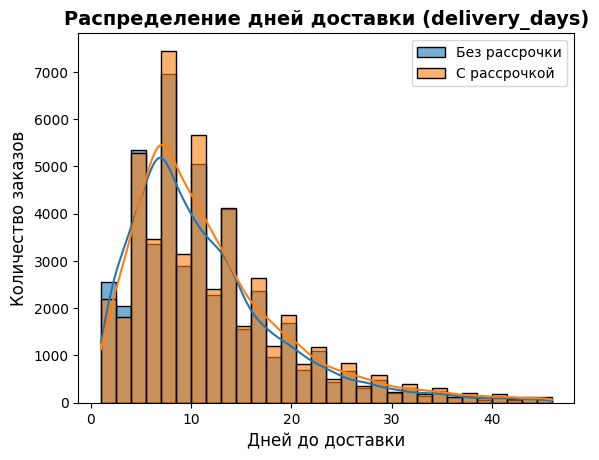

In [74]:
# Форма распределения данных 2 групп: заказы с рассрочкой и без
sns.histplot(data= df_trimmed[df_trimmed['has_installments'] == False],
             x='delivery_days',
             label='Без рассрочки',
             kde=True,
             bins=30,
             alpha=0.6)
sns.histplot(data= df_trimmed[df_trimmed['has_installments'] == True],
             x='delivery_days',
             label='С рассрочкой',
             kde=True,
             bins=30,
             alpha=0.6)

plt.title('Распределение дней доставки (delivery_days)', fontsize=14, fontweight='bold')
plt.xlabel('Дней до доставки', fontsize=12)
plt.ylabel('Количество заказов', fontsize=12)
plt.legend()

plt.show()

Судя по графику, можно поределить правостороннюю ассиметрию - то есть основная масса заказов расположена слева (в меньших сроках доставки). Чем больше срок доставки (если смотреть от среднего срока - 12 дней), тем меньше количество заказов. Это нормально для такой большой выборки и сферы.

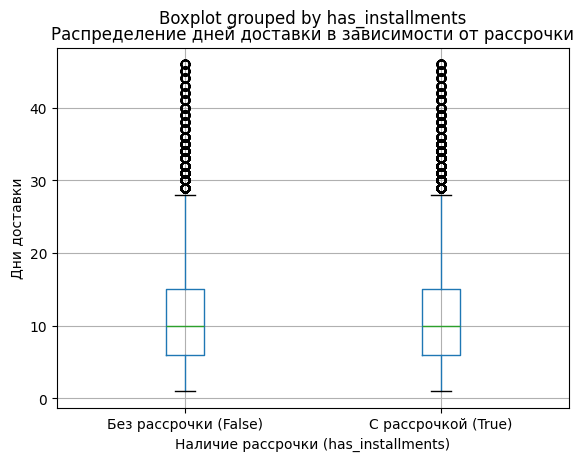

In [73]:
# Иллюстарция данных по delivery_days по группам has_installments
boxplot = df_trimmed.boxplot(column='delivery_days', by='has_installments')
plt.title('Распределение дней доставки в зависимости от рассрочки')
plt.xlabel('Наличие рассрочки (has_installments)')
plt.ylabel('Дни доставки')
plt.xticks([1, 2], ['Без рассрочки (False)', 'С рассрочкой (True)'])

plt.show()


Исходя из графика, можно сказать, что:
*  В обеих группах медианная линия (зеленая черта внутри ящика) находится ровно на уровне 10 дней. Это значит, что половина всех заказов как с рассрочкой, так и без нее, доставляется за 10 дней или быстрее.
*  Сами синие коробки («ящики») имеют одинаковую высоту. Основная масса типичных заказов (центральные 50%) в обеих категориях доставляется в диапазоне от 6 до 15 дней.
*  Нижний ус упирается примерно в 1 день (минимальный срок), а верхний ус заканчивается в районе 28 дней. Всё, что укладывается в 4 недели, считается нормальным поведением системы для обоих типов заказов.
*  Выше 28 дней у обеих групп тянется одинаковый плотный «хвост» из черных кружков-выбросов, доходящий вплоть до 45–46 дней. Это указывает на то, что аномально долгие доставки случаются в обеих категориях с одинаковой частотой и вызваны, скорее всего, внешними факторами (проблемы на складах, удаленность регионов), а не типом оплаты.

Важно уточнить, что этот график распределения данных сделан на основе уже отфильтрованных данных (с усечением 99 и 1 перцентиля).



---



# Вывод по гипотезе

**Бизнес-вопрос:** отличается ли средний срок фактической доставки у заказов с рассрочкой и без рассрочки?

**Гипотезы:**
*  H0: среднее время доставки заказов с рассрочкой (payment_installments > 1) равно среднему времени доставки заказов без рассрочки (payment_installments = 1).
*  H1: среднее время доставки различается.

**Данные и подготовка выборки:**
Использованы df_orders (order_status, order_purchase_timestamp, order_delivered_customer_date) и df_payments (order_id, payment_installments). Оставила только завершённые заказы (order_status = 'delivered') — их 96 478, что на 2 963 меньше исходной таблицы. Признак delivery_days рассчитан как разница между фактической датой доставки (order_delivered_customer_date) и временем покупки (order_purchase_timestamp): анализ ведётся «с точки зрения клиента», поэтому промежуточные этапы (подтверждение платежа, передача логистическому партнёру) и плановая дата доставки не используются. Удалено 8 строк с пропуском в delivery_days (0.008% выборки), отрицательных значений не было. Платежи агрегированы по order_id: payment_installments взят как максимум по заказу, payment_value — как сумма. Заказ считается «с рассрочкой», если payment_installments > 1. Такая сегментация объединяет рассрочку и оплату несколькими методами (например, счёт + ваучер): в обоих случаях клиент распределяет платёж во времени, что и является предметом проверки. После усечения по 1-му и 99-му перцентилям (для устранения выбросов до 195–209 дней) в выборке осталось 95 577 заказов.


**Описательные статистики (после усечения):**
*  N заказов = 95 577
*  Среднее delivery_days = 12
*  Медиана = 10
*  Мин = 1
*  Макс = 46

**Результат теста:**
Использован двусторонний t-тест Уэлча (equal_var=False), не требующий равенства дисперсий. При уровне значимости α = 0.05:
*  t = -10.6039
*  p = 2.96e-26

Отрицательное значение t означает, что среднее в первой группе (без рассрочки) меньше, чем во второй: заказы без рассрочки доставляются в среднем быстрее. p намного меньше α, поэтому H0 отвергается — различие статистически значимо.

**Размер эффекта:**
Разница средних статистически значима (p < 0.001) и отрицательна: без рассрочки доставка в среднем быстрее. Величина эффекта пренебрежимо мала (Hedges' g = 0.07).

**Итог:**
Различие в сроке доставки между заказами с рассрочкой и без неё статистически значимо, но практически пренебрежимо мало: при выборке ~96 тыс. заказов тест чувствителен даже к долям дня. Заказы с рассрочкой доставляются в среднем чуть дольше, однако величина эффекта (Hedges' g = 0.07) слишком мала, чтобы это имело значение для логистики или клиентского опыта. Рекомендации по изменению процессов доставки на основании этого результата не обоснованы.

**Ограничения:**
Анализ охватывает только заказы со статусом delivered — отменённые и зависшие заказы исключены (survivorship bias). Данные Olist ограничены по периоду и не учитывают сезонность и загруженность логистики. Рассрочка — наблюдаемый признак, а не экспериментальный фактор, поэтому вывод описывает ассоциацию, а не причинное влияние. Из выборки удалено 8 строк с пропуском в дате доставки и ~893 строки при усечении по перцентилям.

